# Práctica 5: Introducción al análisis frecuencial de señales

## Integrantes: Sofía Cedeño Vargas, Mariana Paulina Vargas Velez

## 1. Objetivo

Realizar un acercamiento a los conceptos fundamentales en el análisis frecuencial de señales y su aplicación en el análisis de bioseñales.

## 2. Desarrollo de la práctica

En esta práctica se estudiará la representación de señales sinusoidales, el cálculo de la transformada discreta de Fourier (DFT), la transformada inversa de Fourier y la estimación de la densidad espectral de potencia mediante el método de Welch. Posteriormente, estos conceptos se aplicarán al análisis de señales electrocardiográficas (ECG).

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import loadmat

# Configuración general de las gráficas
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.grid'] = True

print("Bibliotecas importadas correctamente.")


Bibliotecas importadas correctamente.



### 4.1. Creación de una señal compuesta por tres componentes sinusoidales

**Enunciado:** Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40, 80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal y utilice la frecuencia de muestreo necesaria para representarla apropiadamente.

**Desarrollo:**

La señal se construye mediante la suma de tres funciones sinusoidales:

$$
x(t) = \sin(2\pi 40t) + \sin(2\pi 80t) + \sin(2\pi 160t)
$$

Se asigna una amplitud unitaria a cada componente, ya que el enunciado no establece amplitudes específicas.

Según el teorema de Nyquist-Shannon, la frecuencia de muestreo debe ser superior al doble de la frecuencia máxima presente en la señal:

$$
F_s > 2F_{\max}
$$

Dado que la frecuencia máxima es de 160 Hz:

$$
2F_{\max}=2(160)=320\text{ Hz}
$$

Por tanto, **320 Hz es el límite de Nyquist**, y para representar correctamente la señal se debe emplear una frecuencia de muestreo superior a este valor.

Se selecciona una frecuencia de muestreo de **1000 Hz**, que permite obtener varias muestras por ciclo de cada componente y visualizar adecuadamente la señal.


In [2]:

# Frecuencias de las componentes (Hz)
f1 = 40
f2 = 80
f3 = 160

# Frecuencia de muestreo seleccionada
Fs = 1000

# Frecuencia máxima y límite de Nyquist
f_max = max(f1, f2, f3)
Fs_limite = 2 * f_max

# Frecuencia fundamental y duración de 10 periodos
f0 = 40
T0 = 1 / f0
duracion = 10 * T0

# Vector de tiempo
t = np.arange(0, duracion, 1 / Fs)

# Componentes sinusoidales
x1 = np.sin(2 * np.pi * f1 * t)
x2 = np.sin(2 * np.pi * f2 * t)
x3 = np.sin(2 * np.pi * f3 * t)

# Señal compuesta
x = x1 + x2 + x3

# Mostrar resultados
print(f"Frecuencia máxima: {f_max} Hz")
print(f"Límite de Nyquist: {Fs_limite} Hz")
print(f"Frecuencia de muestreo utilizada: {Fs} Hz")
print(f"Frecuencia fundamental: {f0} Hz")
print(f"Duración de la señal: {duracion} segundos")
print(f"Número de muestras: {len(x)}")


Frecuencia máxima: 160 Hz
Límite de Nyquist: 320 Hz
Frecuencia de muestreo utilizada: 1000 Hz
Frecuencia fundamental: 40 Hz
Duración de la señal: 0.25 segundos
Número de muestras: 250


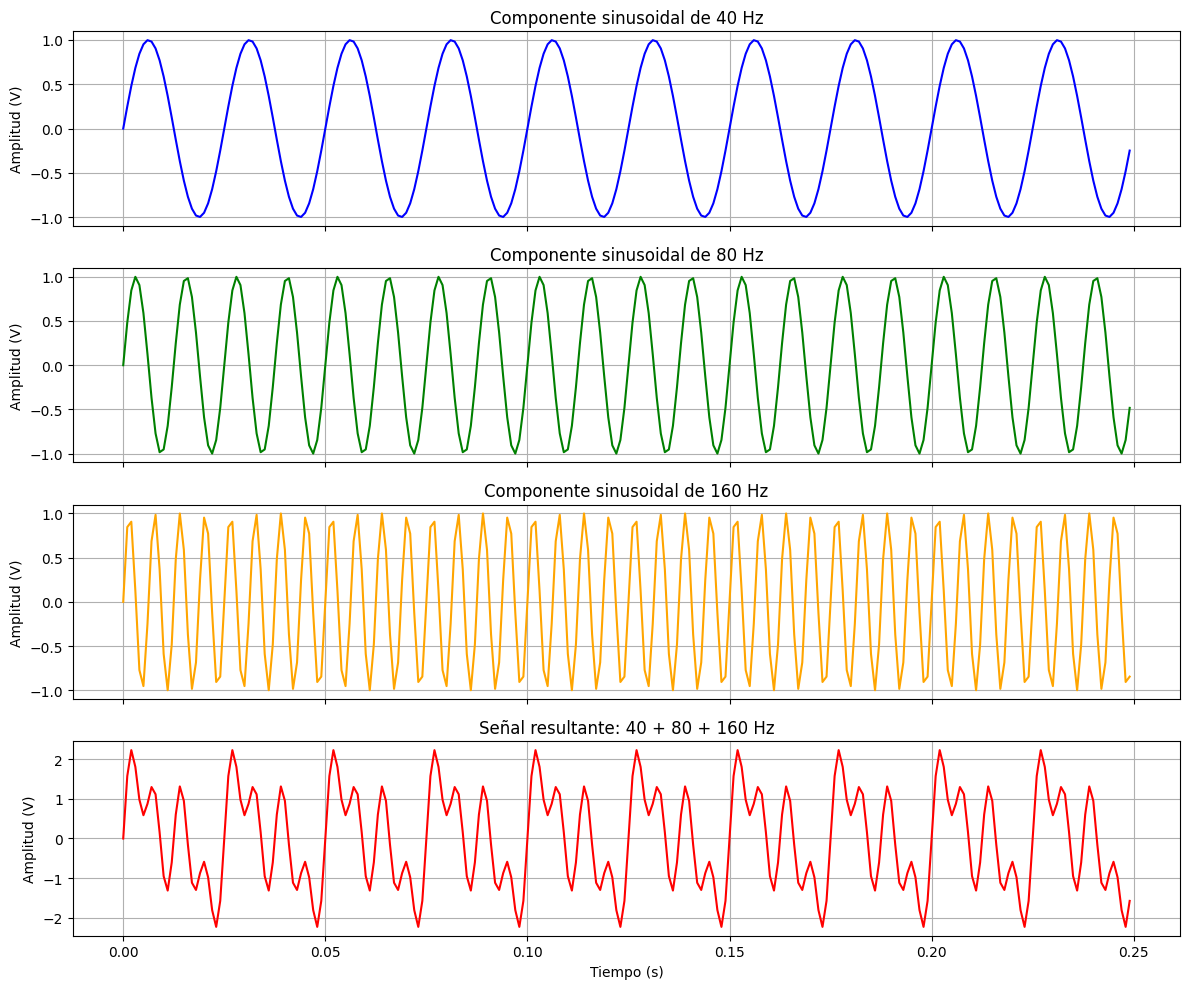

In [3]:

# Graficar las tres componentes y la señal resultante
fig, axs = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

axs[0].plot(t, x1, color='blue')
axs[0].set_title('Componente sinusoidal de 40 Hz')
axs[0].set_ylabel('Amplitud (V)')

axs[1].plot(t, x2, color='green')
axs[1].set_title('Componente sinusoidal de 80 Hz')
axs[1].set_ylabel('Amplitud (V)')

axs[2].plot(t, x3, color='orange')
axs[2].set_title('Componente sinusoidal de 160 Hz')
axs[2].set_ylabel('Amplitud (V)')

axs[3].plot(t, x, color='red')
axs[3].set_title('Señal resultante: 40 + 80 + 160 Hz')
axs[3].set_xlabel('Tiempo (s)')
axs[3].set_ylabel('Amplitud (V)')

plt.tight_layout()
plt.show()



#### Análisis de resultados

Se generó una señal compuesta por tres componentes sinusoidales de 40, 80 y 160 Hz, cada una con amplitud unitaria.

De acuerdo con el teorema de Nyquist-Shannon, se determinó que el límite mínimo de muestreo es de 320 Hz. Sin embargo, se seleccionó una frecuencia de 1000 Hz para representar adecuadamente las componentes de la señal y evitar problemas de aliasing.

En las gráficas se observa que, durante los 0.25 segundos analizados, la componente de 40 Hz realiza 10 ciclos, la de 80 Hz realiza 20 ciclos y la de 160 Hz realiza 40 ciclos.

La señal resultante presenta una forma de onda más compleja debido a la superposición de las tres componentes. A pesar de esto, mantiene un comportamiento periódico, con una frecuencia fundamental de 40 Hz.

Por lo tanto, se logró construir y representar correctamente la señal solicitada, cumpliendo con los criterios de muestreo establecidos.



### 4.2. Transformada de Fourier y espectro de frecuencia

**Enunciado:** Calcule la transformada de Fourier de la señal y grafique el espectro de frecuencia. Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos de la señal).

**Desarrollo:**

La transformada discreta de Fourier (DFT) permite analizar una señal en el dominio de la frecuencia e identificar las componentes sinusoidales que la conforman.

Matemáticamente, la DFT se expresa como:

$$
X(k)=\sum_{n=0}^{N-1}x(n)e^{-j2\pi kn/N}
$$

Donde:

- $X(k)$: coeficiente de Fourier correspondiente al índice de frecuencia $k$.
- $x(n)$: valor de la señal en la muestra $n$.
- $N$: número total de muestras.
- $k$: índice de frecuencia.
- $j$: unidad imaginaria.

Para calcular la DFT se utilizará la función `np.fft.fft()` de NumPy, que implementa el algoritmo de la transformada rápida de Fourier (FFT).

Posteriormente, se calculará el espectro de amplitud de un solo lado, considerando únicamente las frecuencias positivas hasta la frecuencia de Nyquist.

La resolución frecuencial se calcula mediante:

$$
\Delta f = \frac{F_s}{N}
$$

Con los parámetros seleccionados:

$$
\Delta f = \frac{1000}{250}=4\text{ Hz}
$$

Esta resolución permite identificar las componentes ubicadas en 40, 80 y 160 Hz.


Número de muestras: 250
Resolución frecuencial: 4.0 Hz
Frecuencia de Nyquist: 500.0 Hz

Componentes identificadas:
Frecuencia: 40.0 Hz | Amplitud: 1.0000 V
Frecuencia: 80.0 Hz | Amplitud: 1.0000 V
Frecuencia: 160.0 Hz | Amplitud: 1.0000 V


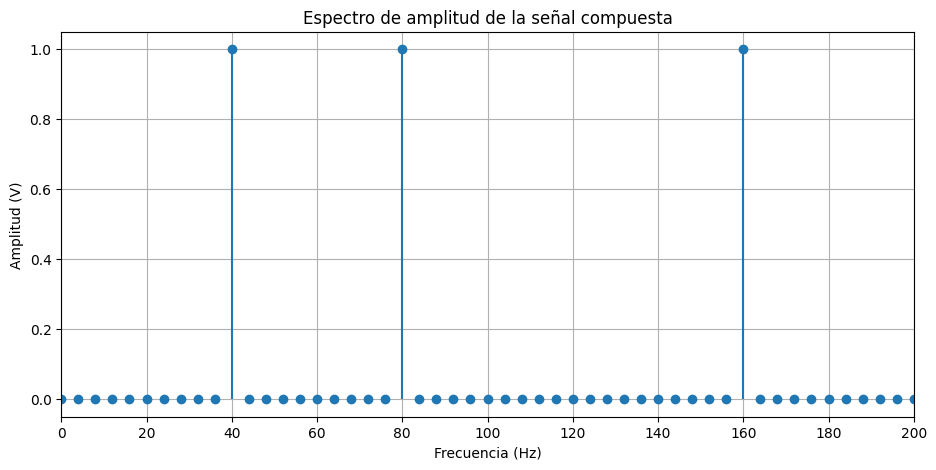

In [4]:

# Número de muestras
N = len(x)

# Transformada rápida de Fourier
X = np.fft.rfft(x)

# Vector de frecuencias positivas
frecuencias = np.fft.rfftfreq(N, d=1/Fs)

# Espectro de amplitud normalizado
amplitudes = np.abs(X) / N
amplitudes[1:-1] *= 2

# Resolución frecuencial
delta_f = Fs / N

# Identificar amplitudes de las frecuencias esperadas
frecuencias_objetivo = [40, 80, 160]

print(f"Número de muestras: {N}")
print(f"Resolución frecuencial: {delta_f} Hz")
print(f"Frecuencia de Nyquist: {Fs/2} Hz")

print("\nComponentes identificadas:")
for f in frecuencias_objetivo:
    indice = np.argmin(np.abs(frecuencias - f))
    print(f"Frecuencia: {frecuencias[indice]:.1f} Hz | "
          f"Amplitud: {amplitudes[indice]:.4f} V")

# Gráfica del espectro
plt.figure(figsize=(11, 5))
plt.stem(frecuencias, amplitudes, basefmt=" ")

plt.title('Espectro de amplitud de la señal compuesta')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud (V)')
plt.xlim(0, 200)
plt.xticks(np.arange(0, 201, 20))
plt.grid(True)
plt.show()



#### Análisis de resultados

Al calcular la transformada discreta de Fourier de la señal compuesta, se identificaron tres picos principales en las frecuencias de 40, 80 y 160 Hz, cada uno con una amplitud de 1 V.

Estos resultados coinciden con las frecuencias y amplitudes utilizadas para construir la señal original en el punto 4.1, lo que demuestra que la transformada de Fourier permite identificar las componentes sinusoidales presentes en una señal.

Se obtuvo una resolución frecuencial de 4 Hz, a partir de las 250 muestras adquiridas con una frecuencia de muestreo de 1000 Hz. Esta resolución fue suficiente para identificar las tres componentes sin que se superpusieran en el espectro.

Además, se comprobó que todas las frecuencias se encuentran por debajo de la frecuencia de Nyquist de 500 Hz.

Por lo tanto, el análisis frecuencial permitió reconocer correctamente las componentes de la señal y verificar que la frecuencia de muestreo seleccionada fue adecuada.



### 4.3. Transformada inversa de Fourier

**Enunciado:** Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier. Aplíquelo a la señal anterior.

**Desarrollo:**

La transformada inversa discreta de Fourier (IDFT) permite reconstruir una señal en el dominio del tiempo a partir de sus componentes en el dominio de la frecuencia.

Matemáticamente, se define como:

$$
x(n)=\frac{1}{N}\sum_{k=0}^{N-1}X(k)e^{j2\pi kn/N}
$$

Donde:

- $x(n)$: señal reconstruida en el dominio del tiempo.
- $X(k)$: coeficientes de la transformada de Fourier.
- $N$: número total de muestras.
- $k$: índice de frecuencia.
- $n$: índice temporal.

En Python, NumPy dispone de la función `np.fft.ifft()` para calcular la transformada inversa de Fourier a partir de un espectro completo.

Como en el punto 4.2 se utilizó `np.fft.rfft()`, que calcula únicamente las frecuencias no negativas de una señal real, se empleará su función inversa correspondiente, `np.fft.irfft()`.

Se aplicará esta función a los coeficientes obtenidos anteriormente y se comparará la señal reconstruida con la señal original para comprobar que ambas coinciden.


Número de muestras originales: 250
Número de muestras reconstruidas: 250
Error absoluto máximo: 7.216449660064e-16
Error cuadrático medio: 9.249866915742e-32


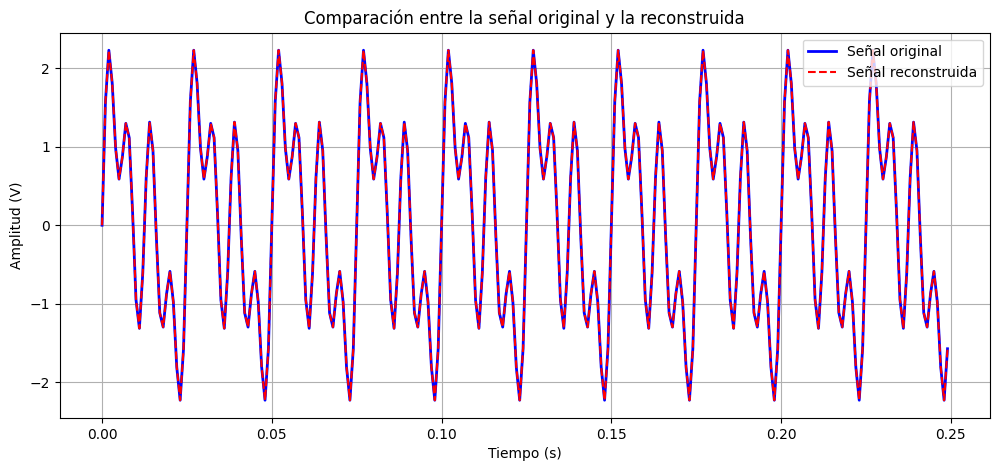

In [5]:

# Reconstruir la señal mediante la transformada inversa
x_reconstruida = np.fft.irfft(X, n=N)

# Calcular el error entre la señal original y la reconstruida
error = x - x_reconstruida

# Error absoluto máximo
error_maximo = np.max(np.abs(error))

# Error cuadrático medio
ecm = np.mean(error**2)

# Mostrar resultados
print(f"Número de muestras originales: {len(x)}")
print(f"Número de muestras reconstruidas: {len(x_reconstruida)}")
print(f"Error absoluto máximo: {error_maximo:.12e}")
print(f"Error cuadrático medio: {ecm:.12e}")

# Comparación gráfica
plt.figure(figsize=(12, 5))

plt.plot(t, x, label='Señal original',
         color='blue', linewidth=2)

plt.plot(t, x_reconstruida, '--',
         label='Señal reconstruida',
         color='red', linewidth=1.5)

plt.title('Comparación entre la señal original y la reconstruida')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.legend()
plt.grid(True)
plt.show()



#### Análisis de resultados

Al aplicar la transformada inversa de Fourier mediante la función `np.fft.irfft()`, se logró reconstruir la señal original a partir de sus componentes en el dominio de la frecuencia.

La señal reconstruida contiene 250 muestras, la misma cantidad que la señal original. Al comparar ambas gráficamente, se observa que sus formas de onda se superponen prácticamente por completo.

Para verificar la precisión de la reconstrucción, se calculó el error absoluto máximo, obteniendo un valor de aproximadamente $7.22 \times 10^{-16}$, y el error cuadrático medio, con un valor de $9.25 \times 10^{-32}$.

Estos errores son prácticamente nulos y corresponden a pequeñas diferencias producidas por la precisión numérica del computador.

Por lo tanto, se comprobó que la transformada inversa permite recuperar correctamente la señal en el dominio del tiempo a partir de su representación frecuencial.



### 4.4. Filtrado de componentes frecuenciales mediante la transformada de Fourier

**Enunciado:** ¿Podría decir que las siguientes líneas aplican un filtro? ¿Por qué?

```python
F1 = np.fft.fft(x)
F2 = np.zeros((len(F1)))
F2[9:13] = F1[9:13]
xr = np.fft.ifft(F2)

fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(t, np.real(xr))
ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)')
plt.show()
```

Extraiga de manera similar cada una de las componentes de la señal.

**Desarrollo:**

Sí, el código realiza un filtrado en el dominio de la frecuencia.

Primero, se calcula la transformada de Fourier de la señal original mediante `np.fft.fft(x)`. Posteriormente, se crea un arreglo de ceros con la misma longitud del espectro y se conservan únicamente algunos coeficientes de Fourier.

La instrucción `F2[9:13] = F1[9:13]` conserva los coeficientes correspondientes a los índices 9, 10, 11 y 12, mientras que los demás permanecen en cero.

Finalmente, la función `np.fft.ifft()` permite regresar al dominio del tiempo utilizando únicamente las componentes frecuenciales seleccionadas.

Por lo tanto, este procedimiento funciona como un filtro frecuencial, porque elimina las componentes que no se encuentran dentro de los índices seleccionados.

Sin embargo, para recuperar correctamente una componente sinusoidal real, es necesario conservar tanto su coeficiente de frecuencia positiva como el correspondiente a la frecuencia negativa, debido a la simetría conjugada de la transformada de Fourier de señales reales.

En esta práctica, la resolución frecuencial es de 4 Hz, por lo que las componentes de 40, 80 y 160 Hz se encuentran en los índices positivos 10, 20 y 40, respectivamente.


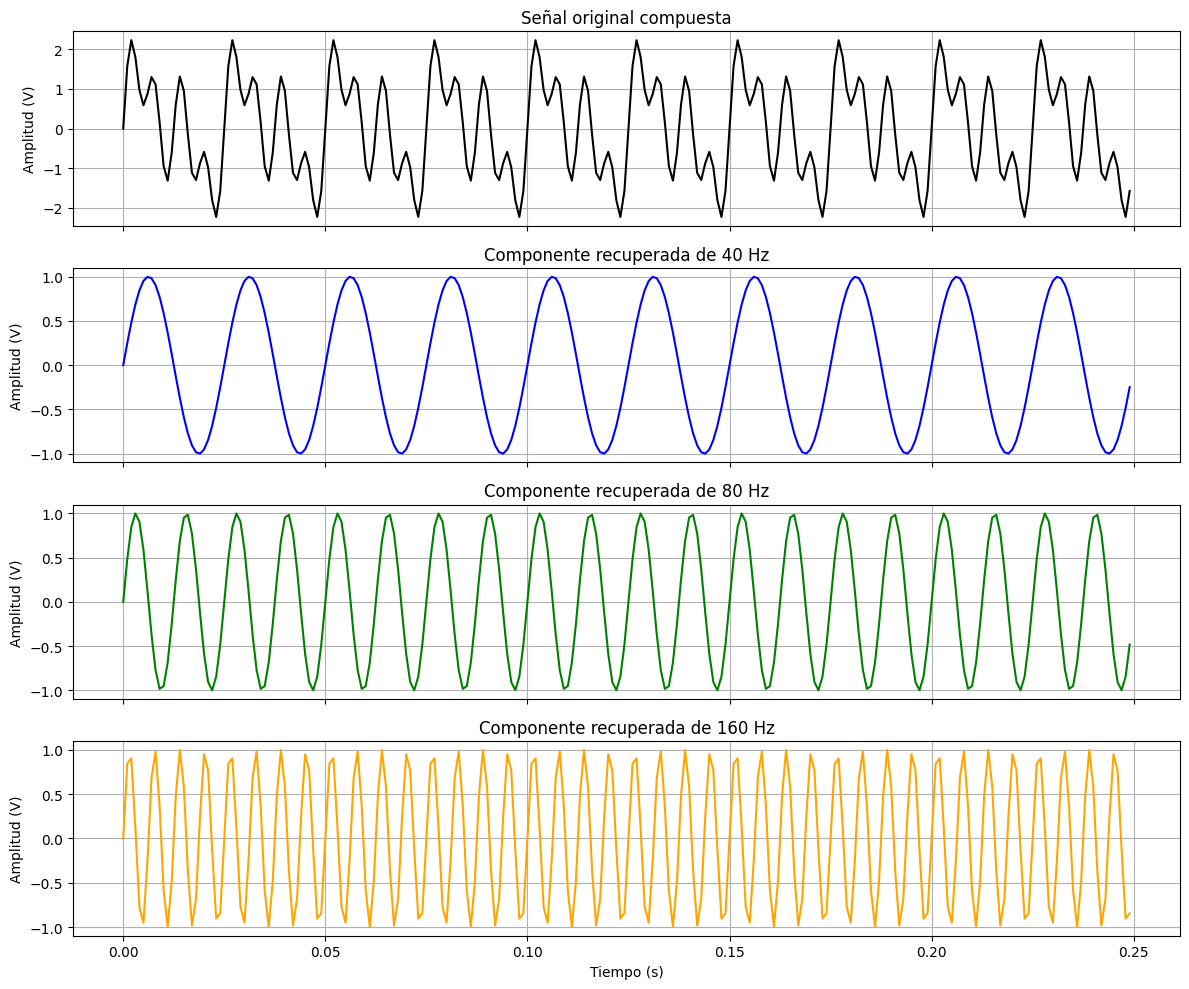

In [6]:

# Transformada completa de Fourier
F1 = np.fft.fft(x)

# Función para extraer una componente frecuencial
def extraer_componente(F1, frecuencia, Fs):
    N = len(F1)

    # Calcular el índice de la frecuencia
    k = int(round(frecuencia * N / Fs))

    # Crear espectro con todos los valores en cero
    F2 = np.zeros(N, dtype=complex)

    # Conservar frecuencia positiva y negativa
    F2[k] = F1[k]
    F2[-k] = F1[-k]

    # Aplicar transformada inversa
    componente = np.fft.ifft(F2)

    return np.real(componente)

# Extraer las componentes
x_40 = extraer_componente(F1, 40, Fs)
x_80 = extraer_componente(F1, 80, Fs)
x_160 = extraer_componente(F1, 160, Fs)

# Representación gráfica
fig, axs = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

axs[0].plot(t, x, color='black')
axs[0].set_title('Señal original compuesta')
axs[0].set_ylabel('Amplitud (V)')

axs[1].plot(t, x_40, color='blue')
axs[1].set_title('Componente recuperada de 40 Hz')
axs[1].set_ylabel('Amplitud (V)')

axs[2].plot(t, x_80, color='green')
axs[2].set_title('Componente recuperada de 80 Hz')
axs[2].set_ylabel('Amplitud (V)')

axs[3].plot(t, x_160, color='orange')
axs[3].set_title('Componente recuperada de 160 Hz')
axs[3].set_xlabel('Tiempo (s)')
axs[3].set_ylabel('Amplitud (V)')

plt.tight_layout()
plt.show()


VERIFICACIÓN DEL FILTRADO
Error absoluto máximo: 4.143127509752e-14
Error cuadrático medio: 4.980853937525e-29


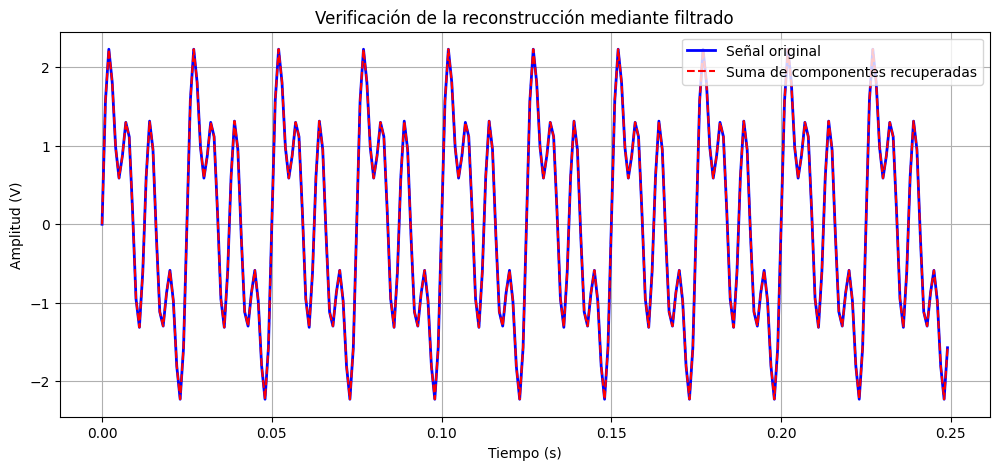

In [7]:

# Reconstruir la señal sumando las componentes recuperadas
x_filtrada = x_40 + x_80 + x_160

# Calcular los errores
error_filtrado = x - x_filtrada
error_maximo_filtrado = np.max(np.abs(error_filtrado))
ecm_filtrado = np.mean(error_filtrado**2)

# Mostrar resultados
print("VERIFICACIÓN DEL FILTRADO")
print(f"Error absoluto máximo: {error_maximo_filtrado:.12e}")
print(f"Error cuadrático medio: {ecm_filtrado:.12e}")

# Comparar gráficamente
plt.figure(figsize=(12, 5))

plt.plot(t, x, color='blue',
         label='Señal original', linewidth=2)

plt.plot(t, x_filtrada, '--', color='red',
         label='Suma de componentes recuperadas',
         linewidth=1.5)

plt.title('Verificación de la reconstrucción mediante filtrado')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.legend()
plt.grid(True)
plt.show()



#### Análisis de resultados

Al aplicar el filtrado en el dominio de la frecuencia, se lograron extraer individualmente las componentes sinusoidales de 40, 80 y 160 Hz.

El procedimiento consistió en calcular la transformada de Fourier de la señal original, conservar únicamente los coeficientes correspondientes a cada frecuencia y aplicar la transformada inversa para recuperar las señales en el dominio del tiempo.

Las gráficas obtenidas muestran que las tres componentes recuperadas conservan sus frecuencias originales y amplitudes cercanas a 1 V.

Para comprobar el procedimiento, se sumaron las tres componentes extraídas y se comparó el resultado con la señal original. Se obtuvo un error absoluto máximo de aproximadamente $4.14 \times 10^{-14}$ y un error cuadrático medio de $4.98 \times 10^{-29}$.

Estos valores son prácticamente cero y demuestran que la señal original pudo reconstruirse a partir de las componentes frecuenciales seleccionadas.

Por lo tanto, se comprobó que es posible realizar un filtrado mediante la transformada de Fourier, eliminando las frecuencias no deseadas y conservando únicamente las componentes de interés.



### 4.5. Cálculo manual del periodograma de Welch

**Enunciado:** Cree una función que calcule manualmente el periodograma de Welch de una señal discreta (usando la DFT), explique paso a paso el algoritmo. Pruébelo en una de las señales construidas anteriormente.

**Desarrollo:**

El método de Welch permite estimar la densidad espectral de potencia (PSD) de una señal, es decir, cómo se distribuye su potencia en función de la frecuencia.

A diferencia de calcular un único periodograma para toda la señal, el método de Welch divide la señal en segmentos, calcula el espectro de potencia de cada uno y posteriormente obtiene su promedio. Esto permite reducir las fluctuaciones de la estimación espectral.

El algoritmo se desarrolla mediante los siguientes pasos:

1. **División de la señal:** se separa la señal original en segmentos de igual longitud.

2. **Solapamiento:** se permite que los segmentos compartan una cantidad determinada de muestras. En este caso se utilizará un solapamiento del 50 %.

3. **Aplicación de una ventana:** cada segmento se multiplica por una ventana de Hann (Hanning), que ayuda a disminuir la fuga espectral causada por los extremos de los segmentos.

4. **Cálculo de la DFT:** se aplica la transformada discreta de Fourier a cada segmento utilizando la FFT.

5. **Cálculo del periodograma:** se calcula el módulo al cuadrado de la transformada y se normaliza según la frecuencia de muestreo y la energía de la ventana.

6. **Promedio de periodogramas:** se promedian las estimaciones espectrales de todos los segmentos para obtener la densidad espectral de potencia mediante el método de Welch.

La estimación de la densidad espectral de potencia de cada segmento se expresa como:

$$
P_m(f_k)=\frac{1}{F_s\sum_{n=0}^{L-1}w^2(n)}
\left|\sum_{n=0}^{L-1}x_m(n)w(n)e^{-j2\pi kn/L}\right|^2
$$

Donde:

- $P_m(f_k)$: densidad espectral de potencia del segmento $m$.
- $F_s$: frecuencia de muestreo.
- $L$: número de muestras por segmento.
- $x_m(n)$: muestras del segmento.
- $w(n)$: ventana aplicada al segmento.
- $f_k$: frecuencia correspondiente al índice $k$.

Finalmente, se obtiene el promedio:

$$
P_{Welch}(f_k)=\frac{1}{M}\sum_{m=1}^{M}P_m(f_k)
$$

Donde $M$ representa el número total de segmentos.

Para las señales reales se utilizará un espectro unilateral, conservando las frecuencias desde 0 Hz hasta la frecuencia de Nyquist y sumando la potencia de las frecuencias negativas a sus correspondientes positivas, excepto en 0 Hz y Nyquist.


In [8]:

def welch_manual(x, Fs, nperseg=125, solapamiento=0.5):
    """
    Calcula manualmente la densidad espectral de potencia
    mediante el método de Welch.

    Parámetros:
    x: señal de entrada
    Fs: frecuencia de muestreo (Hz)
    nperseg: número de muestras por segmento
    solapamiento: proporción de solapamiento (0 a menos de 1)

    Retorna:
    frecuencias: vector de frecuencias en Hz
    psd: densidad espectral de potencia
    """

    # Convertir la señal a un arreglo
    x = np.asarray(x, dtype=float).ravel()

    # Validaciones
    if Fs <= 0:
        raise ValueError("Fs debe ser positiva.")

    if nperseg < 2 or nperseg > len(x):
        raise ValueError("Longitud de segmento no válida.")

    if not 0 <= solapamiento < 1:
        raise ValueError("Solapamiento no válido.")

    # 1. Calcular el número de muestras solapadas
    noverlap = int(nperseg * solapamiento)

    # Desplazamiento entre segmentos
    paso = nperseg - noverlap

    # 2. Crear ventana de Hann periódica
    ventana = signal.windows.hann(nperseg, sym=False)

    # Factor de normalización
    U = np.sum(ventana**2)

    # Almacenar periodogramas
    periodogramas = []

    # 3. Recorrer la señal por segmentos
    for inicio in range(0, len(x) - nperseg + 1, paso):

        segmento = x[inicio:inicio + nperseg]

        # 4. Eliminar el valor medio de cada segmento
        segmento = segmento - np.mean(segmento)

        # 5. Aplicar ventana
        segmento_ventana = segmento * ventana

        # 6. Calcular FFT
        X_segmento = np.fft.rfft(segmento_ventana)

        # 7. Calcular densidad espectral de potencia
        Pxx = np.abs(X_segmento)**2 / (Fs * U)

        # Convertir a espectro unilateral
        if nperseg % 2 == 0:
            Pxx[1:-1] *= 2
        else:
            Pxx[1:] *= 2

        periodogramas.append(Pxx)

    # 8. Promediar todos los periodogramas
    psd = np.mean(periodogramas, axis=0)

    # Vector de frecuencias
    frecuencias = np.fft.rfftfreq(nperseg, d=1/Fs)

    return frecuencias, psd


print("Función manual de Welch creada correctamente.")


Función manual de Welch creada correctamente.


RESULTADOS DEL MÉTODO DE WELCH
Frecuencia de muestreo: 1000 Hz
Muestras por segmento: 125
Muestras solapadas: 62
Número de segmentos: 2
Resolución frecuencial: 8.00 Hz


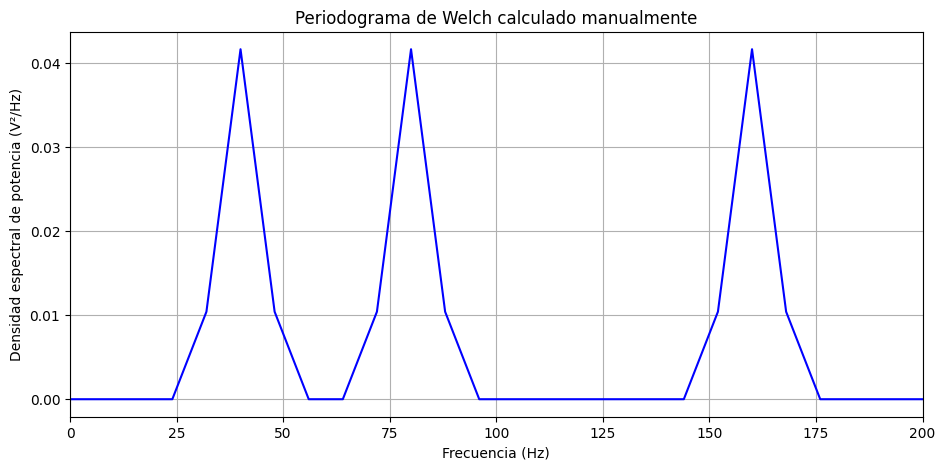

In [9]:

# Parámetros del método de Welch
nperseg = 125
solapamiento = 0.5

# Aplicar la función manual
f_manual, psd_manual = welch_manual(
    x, Fs, nperseg=nperseg,
    solapamiento=solapamiento
)

# Calcular parámetros
noverlap = int(nperseg * solapamiento)
paso = nperseg - noverlap
num_segmentos = 1 + (len(x) - nperseg) // paso
resolucion = Fs / nperseg

# Mostrar resultados
print("RESULTADOS DEL MÉTODO DE WELCH")
print(f"Frecuencia de muestreo: {Fs} Hz")
print(f"Muestras por segmento: {nperseg}")
print(f"Muestras solapadas: {noverlap}")
print(f"Número de segmentos: {num_segmentos}")
print(f"Resolución frecuencial: {resolucion:.2f} Hz")

# Graficar la densidad espectral de potencia
plt.figure(figsize=(11, 5))

plt.plot(f_manual, psd_manual, color='blue')

plt.title('Periodograma de Welch calculado manualmente')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Densidad espectral de potencia (V²/Hz)')
plt.xlim(0, 200)
plt.grid(True)
plt.show()


COMPARACIÓN WELCH MANUAL VS SCIPY
Error absoluto máximo: 6.938893903907e-18
Error cuadrático medio: 1.815112546794e-36


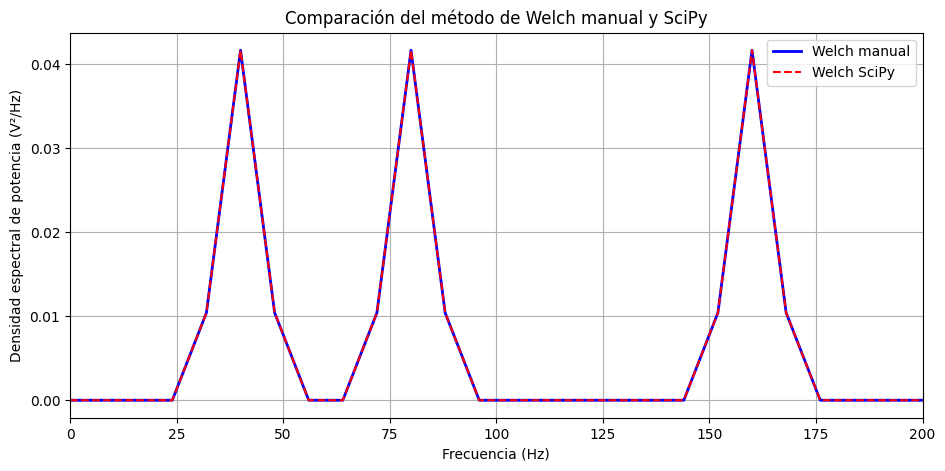

In [10]:

# Calcular Welch utilizando la biblioteca SciPy
f_scipy, psd_scipy = signal.welch(
    x,
    fs=Fs,
    window='hann',
    nperseg=125,
    noverlap=62,
    detrend='constant',
    scaling='density'
)

# Calcular diferencias entre ambos métodos
error_maximo_welch = np.max(np.abs(psd_manual - psd_scipy))
ecm_welch = np.mean((psd_manual - psd_scipy)**2)

# Mostrar resultados
print("COMPARACIÓN WELCH MANUAL VS SCIPY")
print(f"Error absoluto máximo: {error_maximo_welch:.12e}")
print(f"Error cuadrático medio: {ecm_welch:.12e}")

# Comparar gráficamente
plt.figure(figsize=(11, 5))

plt.plot(f_manual, psd_manual,
         color='blue', linewidth=2,
         label='Welch manual')

plt.plot(f_scipy, psd_scipy,
         color='red', linestyle='--',
         linewidth=1.5, label='Welch SciPy')

plt.title('Comparación del método de Welch manual y SciPy')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Densidad espectral de potencia (V²/Hz)')
plt.xlim(0, 200)
plt.legend()
plt.grid(True)
plt.show()



#### Análisis de resultados

Se implementó manualmente el método de Welch utilizando la transformada discreta de Fourier para estimar la densidad espectral de potencia de la señal construida anteriormente.

Para realizar el análisis se utilizó una frecuencia de muestreo de 1000 Hz, una ventana de Hann de 125 muestras y un solapamiento aproximado del 50 % (62 muestras). Con estos parámetros se obtuvieron dos segmentos y una resolución frecuencial de 8 Hz.

La ventana de Hann se seleccionó porque permite reducir la fuga espectral producida por las discontinuidades en los extremos de cada segmento. Por su parte, el solapamiento permite aprovechar mejor las muestras disponibles y obtener varias estimaciones espectrales para calcular su promedio.

El tamaño de ventana de 125 muestras se seleccionó porque permite identificar las componentes de 40, 80 y 160 Hz, manteniendo una resolución frecuencial de 8 Hz.

En el periodograma calculado manualmente se observaron tres picos principales en las frecuencias de 40, 80 y 160 Hz, correspondientes a las componentes sinusoidales de la señal original.

Posteriormente, se compararon los resultados con la función `scipy.signal.welch()`, utilizando los mismos parámetros de procesamiento.

Se obtuvo un error absoluto máximo de aproximadamente $6.94 \times 10^{-18}$ y un error cuadrático medio de $1.82 \times 10^{-36}$.

Estos valores son prácticamente nulos, y las curvas de ambos métodos se superponen, demostrando que la función desarrollada manualmente proporciona resultados equivalentes a los de la biblioteca SciPy.

Por lo tanto, se comprobó el funcionamiento del algoritmo de Welch y su utilidad para identificar las componentes frecuenciales de una señal mediante su densidad espectral de potencia.


-------------------------------------


## Conclusiones

1. Se comprobó la importancia de seleccionar una frecuencia de muestreo adecuada para representar señales discretas. En este caso, una frecuencia de 1000 Hz permitió representar correctamente las componentes sinusoidales de 40, 80 y 160 Hz, evitando problemas de aliasing.

2. La transformada discreta de Fourier permitió identificar las tres componentes de la señal a partir de su espectro de frecuencia. Los picos obtenidos coincidieron con las frecuencias originales y presentaron amplitudes de 1 V.

3. Mediante la transformada inversa de Fourier fue posible reconstruir la señal original con errores numéricos prácticamente nulos, comprobando que la información frecuencial permite recuperar su representación temporal.

4. El filtrado en el dominio de la frecuencia permitió separar individualmente las componentes de 40, 80 y 160 Hz. Al sumar las señales recuperadas se obtuvo nuevamente la señal original, verificando el funcionamiento del procedimiento.

5. La implementación manual del método de Welch permitió estimar la densidad espectral de potencia de la señal e identificar sus componentes frecuenciales. La comparación con `scipy.signal.welch()` mostró resultados prácticamente idénticos, validando el algoritmo desarrollado.
